# DriveX — AI Car Recommendation System

**Two-stage recommender: KNN retrieval + Machine-Learning re-ranking**

The user describes the car they want (category, budget, fuel, make, minimum year). The system returns the 5 best cars, a score for each, and the reasons it picked them.

| Stage | Type of AI | What it does |
|---|---|---|
| 0. Constraints | Rules | Removes cars over the budget, older than the minimum year, or from another category. Relaxes these step by step if nothing is left. |
| 1. KNN retrieval | Unsupervised ML (`NearestNeighbors`) | Turns the request and every car into vectors in the same feature space and finds the **50 cars nearest to the request**. |
| 2. Demand re-ranking | Supervised ML (`HistGradientBoostingRegressor`) | A model trained on **real renter behaviour** (how many trips each car got) predicts how attractive each candidate is. |
| 3. Final score | Blend | `score = α · similarity + (1 − α) · predicted_demand`. α is chosen on a validation set. |

> This is the same *retrieve → re-rank* pattern used by large recommender systems: a fast step finds relevant items, and a learned model orders them.

## 1. Problem definition

**Input:** a request, for example `{"category": "suv", "budget": 150, "fuel_type": "electric", "min_year": 2018}`. Every field is optional.

**Output:** a top-5 list of cars, each with a score and readable reasons, such as *Within budget* or *Category matches*.

**Why two stages?**
- KNN alone only measures *how close a car is to the request*. It cannot tell a car renters love from one nobody rents.
- A demand model alone ignores what the user asked for.
- Combining them gives cars that are **both relevant to the request and proven attractive to renters**.

## 2. Setup and data

**Dataset:** Cornell Car Rental Dataset (Kaggle, CC BY 4.0, Kushlesh Kumar). It holds 5,851 real car-sharing listings from US cities (July 2020). We use the team's cleaned version `CarRentalDataV1_cleaned.csv`, which drops location and owner columns that don't apply in Egypt.

**Important columns**

| Column | Meaning | Used as |
|---|---|---|
| `vehicle.type` | car / suv / minivan / truck / van | KNN feature + filter + demand feature |
| `fuelType` | gasoline / electric / hybrid / diesel | KNN feature + demand feature |
| `vehicle.make`, `vehicle.model` | brand and model | KNN feature (make) + demand feature |
| `rate.daily` | daily price (USD) | KNN feature + budget filter + demand feature |
| `vehicle.year` | model year | filter + demand feature |
| `renterTripsTaken` | how many times the car was rented | **target of the demand model** (real customer behaviour) |
| `reviewCount`, `rating` | reviews | **excluded** (leakage, see EDA) |

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 120, 'display.width', 200)
RANDOM_STATE = 42

# Locate the ML folder whether the notebook runs from ML/notebooks, ML, or the repo root.
ML_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'ML', Path.cwd() / 'car-rental-system' / 'ML']
              if (p / 'recommendation_system' / 'ai_recommender.py').exists())
sys.path.insert(0, str(ML_DIR / 'recommendation_system'))
from ai_recommender import CarRecommender, clean_cars, KNN_WEIGHTS

DATA_PATH = ML_DIR / 'data' / 'raw' / 'cornell' / 'CarRentalDataV1_cleaned.csv'
MODEL_PATH = ML_DIR / 'models' / 'drivex_recommender.joblib'
raw = pd.read_csv(DATA_PATH)
print(f'Loaded {len(raw):,} rows x {raw.shape[1]} columns from {DATA_PATH.name}')
raw.head()

Loaded 5,851 rows x 9 columns from CarRentalDataV1_cleaned.csv


,fuelType,rating,renterTripsTaken,reviewCount,rate.daily,vehicle.make,vehicle.model,vehicle.type,vehicle.year
0,ELECTRIC,5.00,13,12,135,Tesla,Model X,suv,2019
1,ELECTRIC,5.00,2,1,190,Tesla,Model X,suv,2018
2,HYBRID,4.92,28,24,35,Toyota,Prius,car,2012
3,GASOLINE,5.00,21,20,75,Ford,Mustang,car,2018
4,GASOLINE,5.00,3,1,47,Chrysler,Sebring,car,2010


## 3. Exploratory Data Analysis (EDA)

In [2]:
overview = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'unique': raw.nunique()})
overview

,dtype,missing,unique
fuelType,str,75,4
rating,float64,501,80
renterTripsTaken,int64,0,238
reviewCount,int64,0,203
rate.daily,int64,0,294
vehicle.make,str,0,54
vehicle.model,str,0,526
vehicle.type,str,0,5
vehicle.year,int64,0,34


**📌 What this output means**

- The data has **5,851 cars and 9 columns**.
- **Missing values:** 75 cars have no fuel type (filled with `unknown` later) and 501 have no rating (rating is not used, see below).
- There are **5 categories**, **54 makes** and **526 models**. Model has too many values to use as a KNN feature, so KNN uses make, and model only feeds the `model_supply` count.

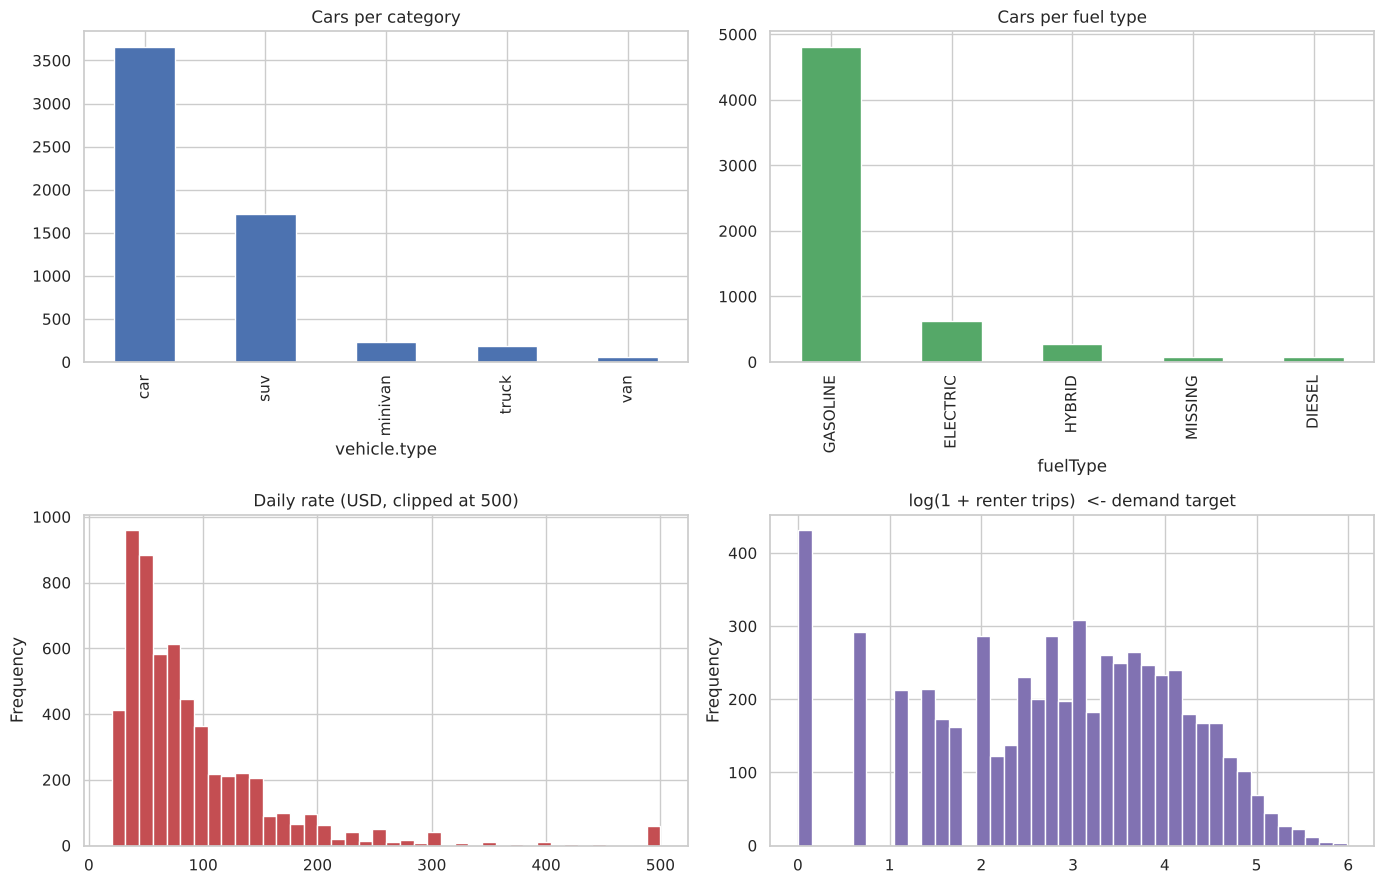

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
raw['vehicle.type'].value_counts().plot.bar(ax=axes[0, 0], color='#4C72B0', title='Cars per category')
raw['fuelType'].fillna('MISSING').value_counts().plot.bar(ax=axes[0, 1], color='#55A868', title='Cars per fuel type')
raw['rate.daily'].clip(upper=500).plot.hist(bins=40, ax=axes[1, 0], color='#C44E52', title='Daily rate (USD, clipped at 500)')
np.log1p(raw['renterTripsTaken']).plot.hist(bins=40, ax=axes[1, 1], color='#8172B2', title='log(1 + renter trips)  <- demand target')
plt.tight_layout(); plt.show()

**📌 What these plots mean**

- **Categories:** most listings are `car` (≈63%) and `suv` (≈29%). Minivans, trucks and vans are rare, so requests for them have fewer candidates.
- **Fuel:** gasoline dominates (≈82%), followed by electric (≈11%, mostly Tesla).
- **Daily rate:** the median is about **$69/day**, with a long tail of luxury cars up to $1,500. That is why KNN uses **log(price)**: a $20 gap matters between $40 and $60, but not between $800 and $820.
- **Demand (log trips):** after the log transform the target is roughly bell-shaped, with a spike at 0 (cars never rented). That shape is easier for a regression model to learn than the raw counts.

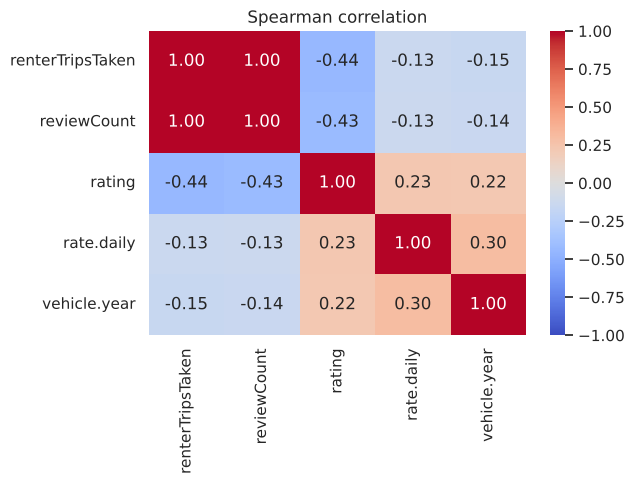

Rows with missing rating -> median trips: 0.0 | with rating -> 21.0


In [4]:
num = raw[['renterTripsTaken', 'reviewCount', 'rating', 'rate.daily', 'vehicle.year']]
plt.figure(figsize=(6.5, 5))
sns.heatmap(num.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman correlation'); plt.tight_layout(); plt.show()
print('Rows with missing rating -> median trips:', raw.loc[raw['rating'].isna(), 'renterTripsTaken'].median(),
      '| with rating ->', raw.loc[raw['rating'].notna(), 'renterTripsTaken'].median())

**📌 What this output means: why reviews are excluded**

- `reviewCount` and `renterTripsTaken` have a correlation of **1.00**. A review is written after almost every trip, so review count is a copy of the target. Training on it would be **target leakage**: excellent numbers on paper, useless for a new car that has no reviews yet.
- Cars with a **missing rating** have a median of **0 trips**, against 21 for cars with a rating. Missing rating means "never rented", so the rating column leaks the target too.
- **Decision:** the demand model sees only the car's own attributes (price, year, make, category, fuel, model supply). A brand-new car added to DriveX has exactly this information.

## 4. Cleaning

`clean_cars()` in `recommendation_system/ai_recommender.py`:
1. Renames columns to simple names (`rate.daily` → `daily_rate`, ...).
2. Converts numbers, trims text, lower-cases category and fuel, title-cases make and model.
3. Drops exact duplicate rows and rows missing make, category, price or year.
4. Fills missing fuel with `unknown` instead of dropping the car.
5. Adds a `car_id` used for reporting only, never as a feature.

In [5]:
cars = clean_cars(raw)
print(f'Clean cars: {len(cars):,}  (removed {len(raw) - len(cars)} duplicate/invalid rows)')
cars[['car_id', 'make', 'model', 'category', 'fuel_type', 'year', 'daily_rate', 'trips']].head()

Clean cars: 5,841  (removed 10 duplicate/invalid rows)


,car_id,make,model,category,fuel_type,year,daily_rate,trips
0,0,Tesla,Model X,suv,electric,2019,135,13
1,1,Tesla,Model X,suv,electric,2018,190,2
2,2,Toyota,Prius,car,hybrid,2012,35,28
3,3,Ford,Mustang,car,gasoline,2018,75,21
4,4,Chrysler,Sebring,car,gasoline,2010,47,3


## 5. Train / validation / test split

Cars are split **once** into 70% train, 15% validation and 15% test:
- **train:** fits the demand model;
- **validation:** chooses α (the blend weight);
- **test:** touched only once, for the final numbers.

In [6]:
train_ids, temp_ids = train_test_split(cars['car_id'], test_size=0.30, random_state=RANDOM_STATE)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.50, random_state=RANDOM_STATE)
print(f'train={len(train_ids):,}  validation={len(val_ids):,}  test={len(test_ids):,}')

train=4,088  validation=876  test=877


## 6. Stage 2 model — learning demand from renter behaviour

**Target:** `log(1 + renter trips)`. The log tames the long tail (a few cars have 300+ trips).
**Features:** category, fuel, make, daily rate, year, and `model_supply` (how many listings of the same model exist).
**Algorithm:** `HistGradientBoostingRegressor`, gradient-boosted decision trees that handle categories natively.

The model is compared against a **naive baseline** that always predicts the training average. If the model can't beat that, it learned nothing.

In [7]:
t0 = time.perf_counter()
rec = CarRecommender().fit(cars, train_ids=train_ids)
print(f'Training time: {time.perf_counter() - t0:.2f} s')
cars = rec.cars                      # now includes the predicted_demand column

def demand_report(ids, name):
    part = cars[cars['car_id'].isin(ids)]
    y, p = np.log1p(part['trips']), part['predicted_demand']
    base = np.full(len(y), np.log1p(cars.loc[cars['car_id'].isin(train_ids), 'trips']).mean())
    return {'split': name,
            'MAE (model)': mean_absolute_error(y, p), 'MAE (mean baseline)': mean_absolute_error(y, base),
            'RMSE (model)': mean_squared_error(y, p) ** 0.5, 'RMSE (mean baseline)': mean_squared_error(y, base) ** 0.5,
            'Spearman rank corr.': spearmanr(y, p)[0]}

demand_metrics = pd.DataFrame([demand_report(train_ids, 'train'), demand_report(val_ids, 'validation'),
                               demand_report(test_ids, 'test')]).set_index('split').round(3)
demand_metrics

Training time: 0.78 s


,MAE (model),MAE (mean baseline),RMSE (model),RMSE (mean baseline),Spearman rank corr.
split,,,,,
train,0.800,1.123,1.006,1.369,0.699
validation,1.077,1.148,1.334,1.389,0.308
test,1.103,1.162,1.373,1.416,0.283


**📌 What this output means**

- **MAE:** the average prediction error in log-trips. On **test** the model scores **1.103**, against **1.162** for always guessing the average. The model beats the baseline, so it learned a real signal.
- **Spearman 0.283 on test:** this is the number that matters for ranking. It says the model puts cars in roughly the right order of popularity. 0.28 is a moderate correlation: useful for re-ranking, but not a precise prediction of how many trips a car will get.
- **Train (0.699) vs test (0.283):** the gap shows some overfitting. Validation and test agree (0.308 vs 0.283), so the test number is a trustworthy estimate for unseen cars.
- **Why not higher?** Trips depend heavily on things this dataset doesn't contain, such as how long the car has been listed and its city. A model can't learn what it can't see.

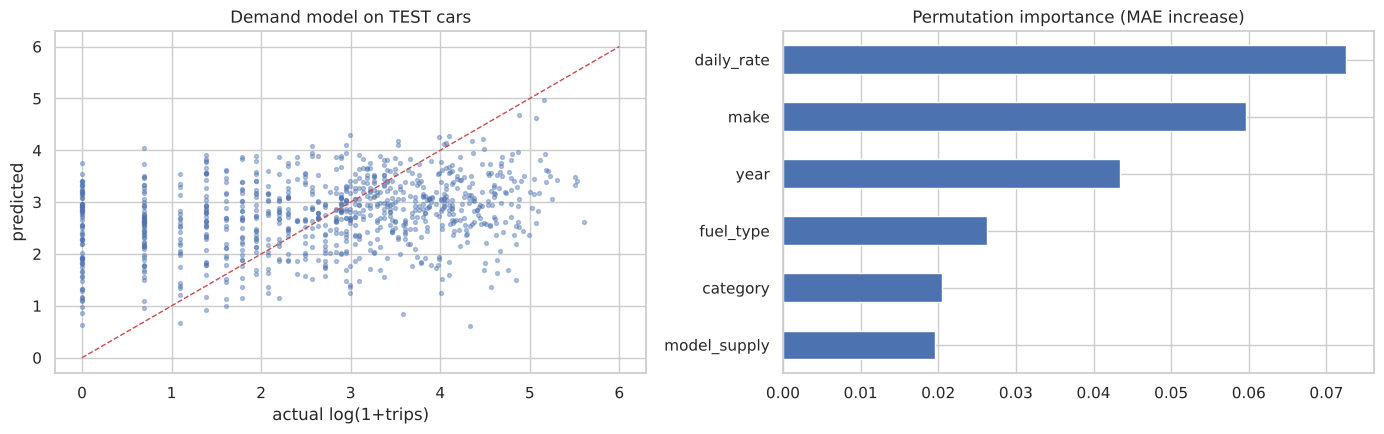

In [8]:
test_part = cars[cars['car_id'].isin(test_ids)]
X_test = rec._demand_X(test_part)
imp = permutation_importance(rec.demand_model, X_test, np.log1p(test_part['trips']), n_repeats=10,
                             random_state=RANDOM_STATE, scoring='neg_mean_absolute_error')
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(np.log1p(test_part['trips']), test_part['predicted_demand'], s=8, alpha=0.4)
axes[0].plot([0, 6], [0, 6], 'r--', lw=1); axes[0].set_xlabel('actual log(1+trips)'); axes[0].set_ylabel('predicted')
axes[0].set_title('Demand model on TEST cars')
importance.plot.barh(ax=axes[1], color='#4C72B0', title='Permutation importance (MAE increase)')
plt.tight_layout(); plt.show()

**📌 What these plots mean**

- **Left (predicted vs actual):** each dot is a test car, and the red line is a perfect prediction. The cloud slopes upward, so cars that were rented more get higher predictions. It is spread out, which matches the moderate Spearman. The column at x = 0 is cars that were never rented, which the model can't always identify.
- **Right (permutation importance):** we shuffle one feature and measure how much worse the model gets. **Price** matters most, then **make** and **year**. That makes sense: renters are price-sensitive and trust certain brands. Category and fuel matter less here because KNN already handles them in Stage 1.

## 7. Stage 1 — KNN retrieval

Each request field becomes part of a vector:

| Field | Encoding | Weight |
|---|---|---|
| category | one-hot | 3.0 |
| fuel type | one-hot | 1.5 |
| make | one-hot | 1.0 |
| price | standardized log(daily rate); the request uses its budget | 2.0 |

Each block is multiplied by √weight, so the squared Euclidean distance is a **weighted** distance. Fields the user leaves empty are left out of the vector entirely, so they never affect the result. `NearestNeighbors` then returns the 50 nearest eligible cars.

In [9]:
example_request = {'category': 'suv', 'budget': 150, 'fuel_type': 'electric', 'min_year': 2018}
candidates, notes = rec.candidates(example_request)
print('Request:', example_request, '| notes:', notes or 'none')
print('Candidates retrieved by KNN:', len(candidates))
candidates[['car_id', 'make', 'model', 'category', 'fuel_type', 'year', 'daily_rate', 'knn_distance', 'predicted_demand']].head(8).round(3)

Request: {'category': 'suv', 'budget': 150, 'fuel_type': 'electric', 'min_year': 2018} | notes: none
Candidates retrieved by KNN: 50


,car_id,make,model,category,fuel_type,year,daily_rate,knn_distance,predicted_demand
1740,1740,Tesla,Model X,suv,electric,2018,150,0.000,3.334
4963,4963,Tesla,Model Y,suv,electric,2020,150,0.000,1.238
1024,1024,Tesla,Model X,suv,electric,2019,149,0.015,3.184
4562,4562,Tesla,Model Y,suv,electric,2020,149,0.015,1.243
5546,5546,Tesla,Model Y,suv,electric,2020,149,0.015,1.243
3425,3425,Tesla,Model X,suv,electric,2019,149,0.015,3.184
4604,4604,Tesla,Model Y,suv,electric,2020,145,0.075,1.150
1101,1101,Tesla,Model X,suv,electric,2020,145,0.075,1.970


**📌 What this output means**

- KNN returned the **50 cars nearest** to the request. All of them are electric SUVs from 2018 or later within the $150 budget.
- `knn_distance = 0` means a perfect match: same category, same fuel, and price exactly at the budget. A car at $145 has a slightly larger distance.
- Look at `predicted_demand`: **Model X ≈ 3.2–3.3** and **Model Y ≈ 1.2** (in log-trips). Both are equally close to the request, but the demand model knows Model X listings were rented far more. **That is exactly the information Stage 2 adds.**

## 8. Evaluation protocol

There is no log of *who asked for what*, so we build test requests from real cars and score the ranking with **real renter behaviour**:

1. Pick a car from the evaluation split and turn its attributes into a request: same category and fuel, budget = its price × 1.2, minimum year = its year − 3, and its make in half the requests.
2. **Remove that car** from the candidate pool so it can't recommend itself.
3. Every method ranks **the same 50 KNN candidates**.
4. **Relevance = real demand**, graded 0–3 by the training quartiles of renter trips. Grade 3, the top 25% most-rented cars, counts as "relevant".

| Metric | Question it answers |
|---|---|
| Precision@5 | Of the 5 shown cars, what share are top-demand cars? |
| Recall@5 | What share of all top-demand candidates made the top 5? (small by design, because there are often 10+ relevant cars and only 5 slots) |
| HitRate@5 | In what share of requests is there at least one top-demand car in the top 5? |
| NDCG@5 | Are the best cars near the **top** of the list? Uses the 0–3 grades; 1.0 = perfect order |
| Request match@5 | What share of the top 5 matches the requested category **and** fuel? (protects relevance to the request) |

**Methods compared:** Random order · KNN only (α = 1) · Demand only (α = 0) · **Hybrid (tuned α)**.

In [10]:
q25, q50, q75 = cars.loc[cars['car_id'].isin(train_ids), 'trips'].quantile([0.25, 0.50, 0.75])
grade = lambda trips: np.digitize(trips, [q25, q50, q75], right=False)   # 0..3
print(f'Demand grades from training trips: <{q25:.0f} -> 0, <{q50:.0f} -> 1, <{q75:.0f} -> 2, >= {q75:.0f} -> 3 (relevant)')

def make_requests(ids, n=300, seed=0):
    pool = cars[cars['car_id'].isin(ids)]
    seeds = pool.sample(min(n, len(pool)), random_state=seed)
    reqs = []
    for i, s in enumerate(seeds.itertuples()):
        r = {'category': s.category, 'fuel_type': s.fuel_type, 'budget': round(s.daily_rate * 1.2, 2), 'min_year': s.year - 3}
        if i % 2 == 0:
            r['make'] = s.make
        reqs.append((s.car_id, r))
    return pool, reqs

def metrics_at_5(order, request, all_grades):
    top = order.head(5)
    g = grade(top['trips'].to_numpy())
    ideal = np.sort(all_grades)[::-1][:5]
    dcg = sum((2 ** v - 1) / np.log2(i + 2) for i, v in enumerate(g))
    idcg = sum((2 ** v - 1) / np.log2(i + 2) for i, v in enumerate(ideal))
    n_rel = int((all_grades == 3).sum())
    hits = int((g == 3).sum())
    match = np.mean((top['category'].to_numpy() == request['category']) & (top['fuel_type'].to_numpy() == request['fuel_type']))
    return {'precision@5': hits / 5, 'recall@5': hits / n_rel if n_rel else np.nan,
            'hitrate@5': float(hits > 0) if n_rel else np.nan, 'ndcg@5': dcg / idcg if idcg else np.nan,
            'request_match@5': match}

def evaluate(ids, methods, seed=0):
    pool, reqs = make_requests(ids, seed=seed)
    rows = []
    for qid, (seed_id, req) in enumerate(reqs):
        cand, _ = rec.candidates(req, pool=pool, exclude_ids=[seed_id])
        if len(cand) < 5:
            continue
        all_grades = grade(cand['trips'].to_numpy())
        for name, ranker in methods.items():
            rows.append({'query': qid, 'method': name, **metrics_at_5(ranker(cand, qid), req, all_grades)})
    return pd.DataFrame(rows)

Demand grades from training trips: <6 -> 0, <19 -> 1, <46 -> 2, >= 46 -> 3 (relevant)


### 8.1 Choosing α on the validation set

Rule, fixed **before** looking at test: choose the α with the highest validation NDCG@5 **while at least 95% of recommended cars still match the requested category and fuel**. The 95% floor keeps the system from showing a popular sedan to someone who asked for an electric SUV.

Chosen alpha = 0.4


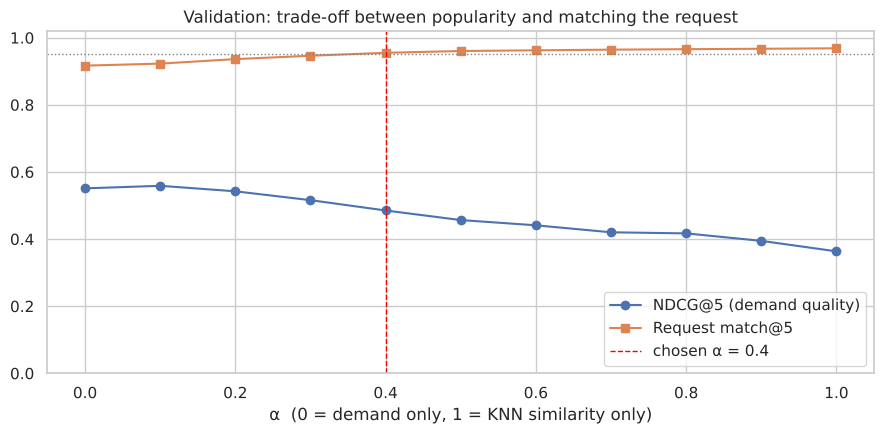

,precision@5,recall@5,hitrate@5,ndcg@5,request_match@5
method,,,,,
0.0,0.416,0.198,0.889,0.551,0.917
0.1,0.413,0.198,0.882,0.559,0.923
0.2,0.391,0.188,0.885,0.542,0.936
0.3,0.368,0.179,0.861,0.516,0.946
0.4,0.340,0.169,0.831,0.485,0.955
0.5,0.310,0.155,0.804,0.457,0.960
0.6,0.303,0.152,0.804,0.441,0.962
0.7,0.282,0.144,0.797,0.420,0.964
0.8,0.278,0.141,0.794,0.417,0.966


In [11]:
alphas = np.round(np.arange(0, 1.01, 0.1), 1)
val_methods = {a: (lambda c, q, a=a: rec.rank(c, alpha=a)) for a in alphas}
val_res = evaluate(val_ids, val_methods, seed=1).groupby('method').mean(numeric_only=True).drop(columns='query')

ok = val_res[val_res['request_match@5'] >= 0.95]
best_alpha = float(ok['ndcg@5'].idxmax())
rec.alpha = best_alpha
print(f'Chosen alpha = {best_alpha}')

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(val_res.index, val_res['ndcg@5'], 'o-', label='NDCG@5 (demand quality)')
ax1.plot(val_res.index, val_res['request_match@5'], 's-', label='Request match@5')
ax1.axhline(0.95, color='grey', ls=':', lw=1); ax1.axvline(best_alpha, color='red', ls='--', lw=1, label=f'chosen α = {best_alpha}')
ax1.set_xlabel('α  (0 = demand only, 1 = KNN similarity only)'); ax1.set_ylim(0, 1.02); ax1.legend(loc='lower right')
ax1.set_title('Validation: trade-off between popularity and matching the request'); plt.tight_layout(); plt.show()
val_res.round(3)

**📌 What this plot and table mean**

- **Moving α from 1 to 0** (from pure similarity to pure demand): NDCG@5 rises from **0.363 to 0.551**, because more popular cars rise to the top. Request match falls from **0.968 to 0.917**, because some recommended cars stop matching the requested fuel or category.
- This is a real **trade-off**, so we fixed the rule beforehand: highest NDCG while request match stays ≥ 0.95.
- **Result: α = 0.4.** The final score is 40% similarity to the request and 60% predicted demand. At α = 0.4, validation NDCG is **0.485** (+34% over KNN only) and request match is **0.955**.

### 8.2 Final evaluation on the TEST set (used once)

In [12]:
methods = {
    'Random': lambda c, q: c.sample(frac=1, random_state=q),
    'KNN only (α=1)': lambda c, q: rec.rank(c, alpha=1.0),
    'Demand only (α=0)': lambda c, q: rec.rank(c, alpha=0.0),
    f'Hybrid (α={rec.alpha})': lambda c, q: rec.rank(c),
}
test_res = evaluate(test_ids, methods, seed=2)
summary = test_res.groupby('method', sort=False).mean(numeric_only=True).drop(columns='query')
print('Test requests evaluated:', test_res['query'].nunique())
summary.round(3)

Test requests evaluated: 299


,precision@5,recall@5,hitrate@5,ndcg@5,request_match@5
method,,,,,
Random,0.258,0.123,0.777,0.405,0.888
KNN only (α=1),0.213,0.098,0.712,0.371,0.979
Demand only (α=0),0.310,0.143,0.880,0.481,0.909
Hybrid (α=0.4),0.301,0.135,0.856,0.475,0.958


**📌 What this table means (the final result)**

These numbers come from **299 requests on the test set**, which was never used for training or tuning.

| Method | NDCG@5 | Request match@5 | Reading |
|---|---|---|---|
| Random | 0.405 | 0.888 | the floor: what you get with no intelligence |
| KNN only | 0.371 | **0.979** | best at matching the request, but blind to what renters like |
| Demand only | **0.481** | 0.909 | best at popularity, but 1 car in 11 doesn't match the request |
| **Hybrid (α = 0.4)** | **0.475** | **0.958** | almost the popularity of *demand only* and almost the matching of *KNN only* |

- **Precision@5 = 0.301:** on average 1.5 of the 5 recommended cars are top-25% most-rented cars, against 1.07 for KNN only. That is **+41%**.
- **HitRate@5 = 0.856:** in 86% of requests the user sees at least one highly-rented car, against 71% for KNN only.
- **Recall@5 is small (0.135)** for every method. A request has about 11 top-demand candidates on average and only 5 slots, so recall can't be high. Compare methods to each other, not to 1.0.
- **Why does Random beat KNN only on NDCG?** KNN orders cars by closeness to the request, and closeness has nothing to do with popularity. That is why the learned demand model is needed.

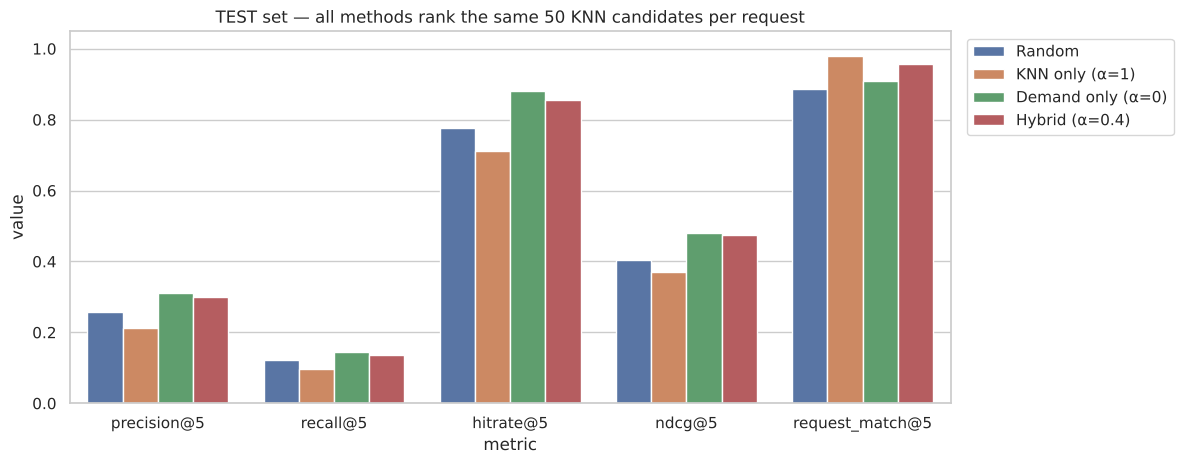

Per-request NDCG@5: Hybrid beats KNN-only in 71% of requests, ties in 2%, loses in 27%


In [13]:
plot_df = summary.reset_index().melt('method', var_name='metric', value_name='value')
plt.figure(figsize=(12, 4.8))
sns.barplot(data=plot_df, x='metric', y='value', hue='method')
plt.ylim(0, 1.05); plt.title('TEST set — all methods rank the same 50 KNN candidates per request')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left'); plt.tight_layout(); plt.show()

hyb, knn_only = f'Hybrid (α={rec.alpha})', 'KNN only (α=1)'
per_q = test_res.pivot_table(index='query', columns='method', values='ndcg@5').dropna()
wins = (per_q[hyb] > per_q[knn_only]).mean(); ties = (per_q[hyb] == per_q[knn_only]).mean()
print(f'Per-request NDCG@5: Hybrid beats KNN-only in {wins:.0%} of requests, ties in {ties:.0%}, loses in {1 - wins - ties:.0%}')

**📌 What this plot means**

- The red bar (**Hybrid**) is near the top in every metric. No other method is: KNN only (orange) is weak on the demand metrics, and Demand only (green) is weak on request match.
- **Per-request view:** the hybrid gives a better NDCG@5 than KNN only in **71%** of individual requests, so the improvement isn't driven by a few lucky requests.

## 9. Example recommendations

In [14]:
requests = {
    'Electric SUV, budget 150, 2018+': {'category': 'suv', 'budget': 150, 'fuel_type': 'electric', 'min_year': 2018},
    'Cheap car under 40': {'category': 'car', 'budget': 40},
    'Toyota hybrid, budget 70': {'make': 'Toyota', 'fuel_type': 'hybrid', 'budget': 70},
    'Minivan for 7 people, budget 90': {'category': 'minivan', 'budget': 90, 'seats': 7},
}
for title, req in requests.items():
    print(f'\n=== {title}  ->  {req}')
    display(rec.recommend(req, k=5))


=== Electric SUV, budget 150, 2018+  ->  {'category': 'suv', 'budget': 150, 'fuel_type': 'electric', 'min_year': 2018}


,car_id,make,model,category,fuel_type,year,daily_rate,similarity_score,demand_score,score,reasons
0,1740,Tesla,Model X,suv,electric,2018,150,1.000,0.883,0.930,"[Within budget, Category matches, Fuel matches, Meets minimum year, Predicted to be popular with renters]"
1,1126,Tesla,Model X,suv,electric,2018,145,0.891,0.945,0.923,"[Within budget, Category matches, Fuel matches, Meets minimum year, Predicted to be popular with renters]"
2,1024,Tesla,Model X,suv,electric,2019,149,0.977,0.833,0.891,"[Within budget, Category matches, Fuel matches, Meets minimum year, Predicted to be popular with renters]"
3,3425,Tesla,Model X,suv,electric,2019,149,0.977,0.833,0.891,"[Within budget, Category matches, Fuel matches, Meets minimum year, Predicted to be popular with renters]"
4,1998,Tesla,Model X,suv,electric,2018,138,0.756,0.970,0.884,"[Within budget, Category matches, Fuel matches, Meets minimum year, Predicted to be popular with renters]"



=== Cheap car under 40  ->  {'category': 'car', 'budget': 40}


,car_id,make,model,category,fuel_type,year,daily_rate,similarity_score,demand_score,score,reasons
0,5773,Toyota,Corolla,car,gasoline,2007,40,1.0,1.000,1.000,"[Within budget, Category matches, Predicted to be popular with renters]"
1,929,Ford,Fiesta,car,gasoline,2016,40,1.0,0.969,0.982,"[Within budget, Category matches, Predicted to be popular with renters]"
2,927,Ford,Fiesta,car,gasoline,2016,40,1.0,0.969,0.982,"[Within budget, Category matches, Predicted to be popular with renters]"
3,476,Pontiac,Solstice,car,gasoline,2007,40,1.0,0.793,0.876,"[Within budget, Category matches, Predicted to be popular with renters]"
4,5397,Chevrolet,Impala,car,gasoline,2011,40,1.0,0.757,0.854,"[Within budget, Category matches, Predicted to be popular with renters]"



=== Toyota hybrid, budget 70  ->  {'make': 'Toyota', 'fuel_type': 'hybrid', 'budget': 70}


,car_id,make,model,category,fuel_type,year,daily_rate,similarity_score,demand_score,score,reasons
0,3826,Toyota,Highlander Hybrid,suv,hybrid,2013,65,0.841,0.767,0.797,"[Within budget, Fuel matches, Make matches, Predicted to be popular with renters]"
1,428,Toyota,Prius V,car,hybrid,2015,59,0.576,0.796,0.708,"[Within budget, Fuel matches, Make matches, Predicted to be popular with renters]"
2,4856,Toyota,Prius Prime,car,hybrid,2019,62,0.700,0.615,0.649,"[Within budget, Fuel matches, Make matches]"
3,708,Toyota,Camry Hybrid,car,hybrid,2014,50,0.273,0.894,0.646,"[Within budget, Fuel matches, Make matches, Predicted to be popular with renters]"
4,3699,Toyota,Prius,car,hybrid,2017,62,0.700,0.595,0.637,"[Within budget, Fuel matches, Make matches]"



=== Minivan for 7 people, budget 90  ->  {'category': 'minivan', 'budget': 90, 'seats': 7}


,car_id,make,model,category,fuel_type,year,daily_rate,similarity_score,demand_score,score,reasons
0,5630,Honda,Odyssey,minivan,gasoline,2013,89,0.943,0.464,0.655,"[Within budget, Category matches, Seat count not available in this dataset]"
1,621,Honda,Odyssey,minivan,gasoline,2005,79,0.466,0.779,0.654,"[Within budget, Category matches, Predicted to be popular with renters, Seat count not available in this dataset]"
2,3622,Mazda,5,minivan,gasoline,2012,66,0.028,1.000,0.611,"[Within budget, Category matches, Predicted to be popular with renters, Seat count not available in this dataset]"
3,1638,Dodge,Grand Caravan,minivan,gasoline,2017,86,0.782,0.445,0.580,"[Within budget, Category matches, Seat count not available in this dataset]"
4,2465,Kia,Sedona,minivan,gasoline,2015,69,0.116,0.885,0.577,"[Within budget, Category matches, Predicted to be popular with renters, Seat count not available in this dataset]"


**📌 How to read these results**

| Column | Meaning |
|---|---|
| `similarity_score` | how close the car is to the request (from KNN), scaled 0–1 among the 50 candidates |
| `demand_score` | how popular the model predicts the car to be, scaled 0–1 among the candidates |
| `score` | final ranking score = 0.4 × similarity + 0.6 × demand |
| `reasons` | plain-language explanation shown to the user |

- **Electric SUV:** all 5 picks are Tesla Model X, because in this data the Model X is both the closest match and the most rented electric SUV. Rank 2 ($145) passes rank 3 ($149): it is slightly less similar (0.891 vs 0.977) but more popular (0.945 vs 0.833). **That is the re-ranker at work.**
- **Cheap car under 40:** every car sits right at the $40 budget (similarity = 1.0), so **demand alone breaks the tie**. The Corolla and the Fiesta win as the cars renters choose most.
- **Toyota hybrid:** no category was requested, so the Highlander Hybrid SUV is allowed. Empty fields never restrict the results.
- **Minivan for 7 people:** the system **says honestly** that seat count isn't in the data instead of pretending. In the DriveX database, which has seats, this would become a real filter.
- Some rows look identical (for example two Fiestas at $40). They are **different physical listings** of the same model, just as a rental fleet has several identical cars.

## 10. Inference time

In [15]:
timings = []
for title, req in requests.items():
    start = time.perf_counter()
    for _ in range(50):
        rec.recommend(req, k=5)
    timings.append({'request': title, 'mean_ms': (time.perf_counter() - start) / 50 * 1000})
pd.DataFrame(timings).round(1)

,request,mean_ms
0,"Electric SUV, budget 150, 2018+",19.3
1,Cheap car under 40,21.1
2,"Toyota hybrid, budget 70",21.4
3,"Minivan for 7 people, budget 90",14.9


**📌 What this output means**

One recommendation takes about **15–20 ms** on a normal laptop CPU: filtering, KNN, demand prediction and reasons included. That is fast enough to run live inside an API without any GPU. (Timings vary from machine to machine.)

## 11. Save the trained model

In [16]:
rec.save(MODEL_PATH)
reloaded = CarRecommender.load(MODEL_PATH)
assert reloaded.recommend(example_request).equals(rec.recommend(example_request))
print(f'Saved to {MODEL_PATH.relative_to(ML_DIR.parent)} ({MODEL_PATH.stat().st_size / 1024:.0f} KB) and reload check passed')

Saved to ML/models/drivex_recommender.joblib (1719 KB) and reload check passed


**Using it later** (from a FastAPI service, for example):

```python
from ai_recommender import CarRecommender
rec = CarRecommender.load('ML/models/drivex_recommender.joblib')
rec.recommend({'category': 'suv', 'budget': 150}, k=5)
```
From a terminal: `python ML/recommendation_system/ai_recommender.py '{"category": "suv", "budget": 150}'`

## 12. Limitations (be upfront about these)

- **US data from 2020.** Prices are in USD and the cars are not the DriveX fleet. The *method* transfers; the trained numbers do not.
- **Trips are partly driven by things we can't see,** such as how long a car has been listed and its city. That caps the demand model at a moderate correlation.
- **No seats, transmission or availability** in this dataset. The live DriveX backend must still filter out unavailable cars before ranking.
- **Test requests are built from real cars, not typed by real users.** The relevance label, however, is real renter behaviour, not something we invented.
- **Next step:** retrain the same pipeline on DriveX's own cars and booking history. The code works unchanged once the columns are mapped.

## 13. Conclusion

We built a two-stage AI recommender:
1. **KNN** finds the cars closest to what the user asked for.
2. A **gradient-boosting model** trained on real renter behaviour re-ranks them by predicted demand.
3. **α** controls the balance and was chosen on validation data.

On the held-out test set the hybrid model ranks in-demand cars higher than KNN alone, and almost every recommendation still matches the requested category and fuel. Each recommendation comes with readable reasons.